# Chatbot con un Modelo de Lenguaje

## Objetivo

En esta práctica construiremos paso a paso un **chatbot basado en un modelo de lenguaje**.

El objetivo principal no es profundizar en todos los detalles técnicos de los modelos de lenguaje, sino comprender de manera general:

- Qué es un modelo de lenguaje.
- Cómo recibe una pregunta del usuario.
- Cómo podemos proporcionarle información adicional.
- Cómo se construye un **prompt**.
- Cómo el modelo genera una respuesta.
- Cómo podemos integrar estos elementos para construir un chatbot.

Al finalizar podremos observar el flujo completo:

**Usuario → Pregunta → Contexto → Prompt → Modelo de lenguaje → Respuesta**

## ¿Qué vamos a construir?

Hasta ahora hemos visto diferentes formas en las que un sistema de Inteligencia Artificial puede procesar información y tomar decisiones.

Por ejemplo:

**Sistema basado en reglas**

`Hechos + Reglas → Resultado`

**Sistema experto**

`Hechos + Base de conocimiento + Motor de inferencia → Conclusión`

Ahora veremos una forma diferente de trabajar con Inteligencia Artificial:

**Chatbot con un modelo de lenguaje**

`Pregunta + Contexto + Instrucciones → Modelo de lenguaje → Respuesta`

En este caso, no escribiremos todas las posibles respuestas mediante reglas.

Utilizaremos un **modelo de lenguaje**, capaz de generar texto a partir de las instrucciones y del contexto que le proporcionemos.

## ¿Qué es un modelo de lenguaje?

Un **modelo de lenguaje** es un sistema de Inteligencia Artificial diseñado para trabajar con lenguaje.

Puede realizar tareas como:

- completar texto;
- responder preguntas;
- resumir información;
- clasificar texto;
- generar explicaciones;
- mantener una conversación.

Los modelos de lenguaje modernos reciben un texto de entrada y generan una continuación considerando los patrones aprendidos durante su entrenamiento.

Cuando estos modelos tienen una gran cantidad de parámetros y han sido entrenados con grandes cantidades de texto, suelen denominarse **LLM (Large Language Models)**.

En esta práctica utilizaremos un modelo ya existente.

**No vamos a crear un LLM desde cero.**

Nuestro objetivo será aprender cómo podemos utilizarlo como parte de un sistema más grande.

## 1. Preparación del entorno

Antes de utilizar un modelo de lenguaje necesitamos preparar nuestro entorno de trabajo.

En esta sección realizaremos tres tareas:

1. **Instalar las bibliotecas** necesarias.
2. **Importar las herramientas** que utilizaremos en Python.
3. **Conectarnos con Hugging Face** para poder acceder a los modelos.

### ¿Qué es Hugging Face?

**Hugging Face** es una plataforma que permite acceder a modelos, datasets y herramientas relacionadas con Inteligencia Artificial.

En lugar de entrenar un modelo de lenguaje desde cero, podemos utilizar un **modelo previamente entrenado** disponible en esta plataforma.

### ¿Por qué necesitamos un token?

Algunos recursos de Hugging Face requieren identificar al usuario que los está utilizando.

Para ello utilizaremos un **token de acceso**.

El token funciona de manera similar a una contraseña, por lo que **no debemos escribirlo directamente en nuestro código**.

En Google Colab lo almacenaremos utilizando **Secrets**:

`HF_TOKEN`

De esta forma nuestro código puede utilizarlo sin mostrarlo públicamente.

### **COLAB SECRETS**

Para no exponer tu ***token*** directamente en el código, Colab ofrece un panel de ***Secrets*** (ícono de llave en la barra lateral izquierda) donde puedes guardarlo de forma segura. Para este Tema necesitas un ***token de Hugging Face*** (el modelo que usamos es de acceso libre, no requiere solicitar permiso especial).

In [ ]:
# ============================================================
# 1. INSTALACIÓN Y PREPARACIÓN DE LAS HERRAMIENTAS
# ============================================================

# Instalamos las bibliotecas que utilizaremos durante la práctica.
# --quiet reduce los mensajes que aparecen durante la instalación.
!pip install transformers peft accelerate trl sentence-transformers --quiet


# ------------------------------------------------------------
# Importamos las herramientas necesarias
# ------------------------------------------------------------

# PyTorch: biblioteca utilizada para trabajar con modelos de IA.
import torch

# Permite acceder de forma segura a datos guardados en
# "Secrets" de Google Colab, como nuestro token de Hugging Face.
from google.colab import userdata

# Función que permite iniciar sesión en Hugging Face.
from huggingface_hub import login

# Herramientas de Transformers:
# AutoTokenizer convierte el texto en tokens que entiende el modelo.
# AutoModelForCausalLM permite cargar un modelo generador de texto.
from transformers import AutoModelForCausalLM, AutoTokenizer

# Configuramos Transformers para mostrar únicamente errores importantes
# y evitar demasiados mensajes técnicos en pantalla.
from transformers.utils import logging
logging.set_verbosity_error()


# ------------------------------------------------------------
# Iniciamos sesión en Hugging Face
# ------------------------------------------------------------

# Recuperamos el token llamado "HF_TOKEN" desde los Secrets de Colab
# y lo utilizamos para autenticarnos en Hugging Face.
#
# De esta forma NO escribimos el token directamente en el código.
login(token=userdata.get('HF_TOKEN'))

print("Sesión de Hugging Face iniciada correctamente.")

Sesión de Hugging Face iniciada correctamente.


## 2. Creación de la base de conocimiento

Nuestro chatbot necesita información que pueda consultar para responder preguntas.

En este ejemplo construiremos una pequeña **base de conocimiento** sobre las políticas de una biblioteca.

La base contendrá información como:

- tiempo máximo de préstamo;
- multas por devoluciones tardías;
- restricciones para ciertos libros.

### ¿Cómo buscará el chatbot la información?

Podríamos buscar palabras exactamente iguales, pero esto tendría una limitación.

Por ejemplo, el usuario podría preguntar:

> "¿Cuánto tiempo puedo quedarme con un libro?"

Mientras que nuestra base de conocimiento dice:

> "Los libros se prestan por un máximo de 15 días."

Las frases no utilizan exactamente las mismas palabras, pero expresan ideas relacionadas.

Para poder comparar su **significado**, utilizaremos **embeddings**.

### ¿Qué es un embedding?

Un embedding es una representación numérica de un texto.

De forma simplificada:

`Texto → Modelo de embeddings → Vector de números`

Por ejemplo:

`"Los libros se prestan por 15 días" → [0.12, -0.31, 0.08, ...]`

Estos números permiten que la computadora compare matemáticamente qué textos tienen significados similares.

### Idea clave

El modelo de lenguaje no buscará directamente dentro de todos nuestros documentos.

Primero utilizaremos los **embeddings para encontrar la información más relacionada con la pregunta del usuario**.

Más adelante utilizaremos esa información como contexto para generar la respuesta.

### ¿Qué es RAG?

**RAG** significa **Retrieval-Augmented Generation**  
(Generación Aumentada por Recuperación).

La idea consiste en combinar dos procesos:

1. **Retrieval (Recuperación):** buscar información relevante en una fuente externa.
2. **Generation (Generación):** proporcionar esa información a un modelo de lenguaje para que genere una respuesta.

El flujo general será:

`Pregunta → Buscar información relevante → Proporcionarla al LLM → Generar respuesta`

### ¿Por qué utilizar RAG?

Un modelo de lenguaje genera respuestas utilizando el conocimiento adquirido durante su entrenamiento, pero puede:

- no conocer información específica de nuestra organización;
- tener información desactualizada;
- generar información incorrecta.

Con RAG podemos proporcionarle **información externa relevante como contexto** antes de pedirle que responda.

Esto puede ayudar a reducir las respuestas incorrectas, aunque **no garantiza eliminar completamente las alucinaciones**.

In [ ]:
# ============================================================
# 2. CREACIÓN DE LA BASE DE CONOCIMIENTO
# ============================================================

# Importamos SentenceTransformer.
# Esta herramienta nos permitirá convertir textos en embeddings,
# es decir, representaciones numéricas de su significado.
from sentence_transformers import SentenceTransformer

# NumPy nos permitirá trabajar con arreglos y operaciones numéricas.
# Lo utilizaremos posteriormente para trabajar con los embeddings.
import numpy as np


# ------------------------------------------------------------
# Cargamos el modelo de embeddings
# ------------------------------------------------------------

# Utilizamos un modelo previamente entrenado que puede trabajar
# con diferentes idiomas, incluyendo español.
modelo_embeddings = SentenceTransformer(
    'paraphrase-multilingual-MiniLM-L12-v2'
)


# ------------------------------------------------------------
# Creamos nuestra base de conocimiento
# ------------------------------------------------------------

# Cada elemento de la lista representa un fragmento de conocimiento
# que posteriormente podrá ser consultado por nuestro chatbot.
documentos = [
    "Los libros se prestan por un máximo de 15 días, con posibilidad de renovar una vez si nadie más lo ha solicitado.",

    "Las devoluciones tardías generan una multa de $10 por día de retraso, hasta un máximo de $150 por libro.",

    "Los libros de la sección de reserva (material de examen) solo se consultan dentro de la biblioteca, no se prestan a domicilio."
]


# ------------------------------------------------------------
# Convertimos los documentos en embeddings
# ------------------------------------------------------------

# El modelo transforma cada texto de nuestra base de conocimiento
# en un vector de números.
#
# Estos vectores permitirán comparar posteriormente el significado
# de una pregunta con el significado de nuestros documentos.
embeddings_documentos = modelo_embeddings.encode(documentos)


# Mostramos las dimensiones de la matriz generada.
#
# El primer número corresponde a la cantidad de documentos.
# El segundo corresponde a la cantidad de valores que contiene
# el embedding generado para cada documento.
print("Embeddings generados:", embeddings_documentos.shape)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings generados: (3, 384)


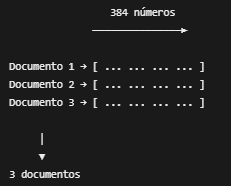

“¿Por qué tenemos 3 filas?”

Porque tenemos 3 documentos.

“¿Y qué representan los 384 valores?”

Son las características numéricas que utiliza este modelo para representar cada texto en su espacio de embeddings. No significa que nosotros hayamos definido 384 características; esa representación la produce el modelo.
Y conectaría inmediatamente con lo que viene:
“Ya convertimos nuestra base de conocimiento a números. Ahora, cuando el usuario haga una pregunta, tendremos que hacer exactamente lo mismo con esa pregunta. Si tenemos el documento y la pregunta representados como vectores, podremos medir cuál documento es más parecido a la pregunta.”

“Ya convertimos nuestra base de conocimiento a números. Ahora, cuando el usuario haga una pregunta, tendremos que hacer exactamente lo mismo con esa pregunta. Si tenemos el documento y la pregunta representados como vectores, podremos medir cuál documento es más parecido a la pregunta.”

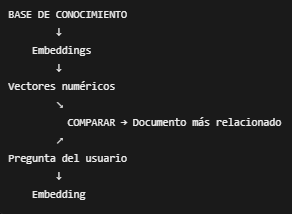

## 3. Recuperación de información: RAG

Ya tenemos una **base de conocimiento** y convertimos cada uno de sus documentos en embeddings.

Ahora necesitamos responder una pregunta:

> ¿Cómo encuentra el chatbot qué información de la base de conocimiento puede ayudar a responder la pregunta del usuario?

Para ello utilizaremos una técnica llamada **RAG**.



### En esta celda...

Todavía no utilizaremos el modelo de lenguaje.

Implementaremos únicamente la primera parte de RAG:

**RECUPERACIÓN**

`Pregunta → Embedding → Comparación → Fragmento más relacionado`

Más adelante enviaremos ese fragmento al modelo de lenguaje para generar la respuesta.

In [ ]:
# ============================================================
# 3. RECUPERACIÓN DE INFORMACIÓN (RAG)
# ============================================================

# Creamos una función que recibirá la pregunta del usuario
# y buscará el fragmento más relacionado dentro de nuestra
# base de conocimiento.
def buscar_fragmento(pregunta):

    # --------------------------------------------------------
    # 1. Convertimos la pregunta en un embedding
    # --------------------------------------------------------

    # Utilizamos el MISMO modelo de embeddings que usamos
    # anteriormente con los documentos.
    #
    # Así, tanto los documentos como la pregunta estarán
    # representados numéricamente de forma comparable.
    embedding_pregunta = modelo_embeddings.encode([pregunta])


    # --------------------------------------------------------
    # 2. Comparamos la pregunta con todos los documentos
    # --------------------------------------------------------

    # Calculamos qué tan relacionada está la pregunta
    # con cada uno de los documentos de nuestra base.
    #
    # El resultado será un valor de similitud para
    # cada documento.
    similitudes = np.dot(
        embeddings_documentos,
        embedding_pregunta.T
    ).flatten()


    # --------------------------------------------------------
    # 3. Buscamos el documento con mayor similitud
    # --------------------------------------------------------

    # np.argmax() devuelve la posición del valor más alto.
    #
    # Esa posición corresponde al documento que tiene
    # mayor similitud con la pregunta.
    indice_mas_similar = np.argmax(similitudes)


    # --------------------------------------------------------
    # 4. Devolvemos el fragmento encontrado
    # --------------------------------------------------------

    # Utilizamos el índice encontrado para recuperar
    # el texto original de nuestra base de conocimiento.
    return documentos[indice_mas_similar]


# ------------------------------------------------------------
# Probamos nuestro sistema de recuperación, ojo aqui no hay IA
# ------------------------------------------------------------

buscar_fragmento(
    "¿Puedo llevarme a casa un libro de la sección de reserva?"
)

'Los libros se prestan por un máximo de 15 días, con posibilidad de renovar una vez si nadie más lo ha solicitado.'

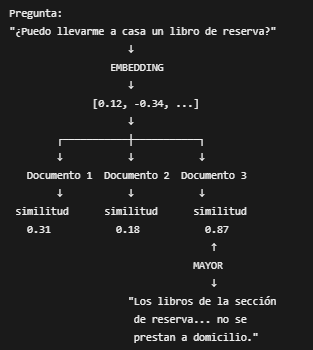

“No necesitamos que la pregunta tenga las mismas palabras que el documento. Queremos encontrar el texto cuyo significado sea más parecido.”

## 4. Carga del modelo de lenguaje

Hasta este momento hemos preparado nuestra base de conocimiento y el mecanismo para recuperar información relevante.

Ahora necesitamos el componente que será capaz de **generar texto**: el modelo de lenguaje.

En esta práctica utilizaremos:

**TinyLlama-1.1B-Chat**

TinyLlama es un modelo de lenguaje previamente entrenado. Esto significa que **no vamos a entrenar un modelo desde cero**; partiremos de un modelo que ya puede procesar y generar texto.

### Modelo y tokenizer

Para utilizar el modelo necesitamos cargar dos elementos:

**Tokenizer**

Convierte el texto que escribimos en **tokens**, representaciones numéricas que el modelo puede procesar.

`Texto → Tokenizer → Tokens`

**Modelo**

Recibe esos tokens y realiza los cálculos necesarios para generar nuevos tokens como respuesta.

`Tokens → Modelo → Nuevos tokens → Texto`

De forma simplificada, el proceso será:

**Pregunta → Tokenizer → Modelo → Respuesta**



In [ ]:
# ============================================================
# 4. CARGA DEL MODELO BASE
# ============================================================

# Indicamos qué modelo de Hugging Face vamos a utilizar.
#
# En este caso utilizaremos TinyLlama, un modelo de lenguaje
# previamente entrenado y preparado para conversaciones.
modelo_base = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"


# ------------------------------------------------------------
# Cargamos el tokenizer
# ------------------------------------------------------------

# El tokenizer se encarga de transformar el texto que escribimos
# en tokens que el modelo puede procesar.
tokenizer = AutoTokenizer.from_pretrained(modelo_base)


# ------------------------------------------------------------
# Cargamos el modelo de lenguaje
# ------------------------------------------------------------

# AutoModelForCausalLM carga el modelo encargado de generar texto.
#
# dtype=torch.float16:
# utiliza números de 16 bits para reducir el uso de memoria.
#
# device_map="auto":
# permite que Transformers seleccione automáticamente
# el dispositivo disponible para ejecutar el modelo
# (por ejemplo, la GPU de Google Colab).
modelo = AutoModelForCausalLM.from_pretrained(
    modelo_base,
    dtype=torch.float16,
    device_map="auto"
)


# Confirmamos que el modelo fue cargado correctamente.
print("Modelo base cargado:", modelo_base)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Modelo base cargado: TinyLlama/TinyLlama-1.1B-Chat-v1.0


El tokenizer actúa como un traductor entre nuestro texto y la representación que puede procesar el modelo.
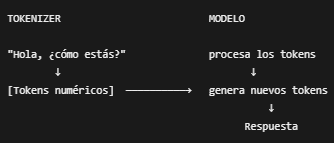


## 5. Preparación de la función para generar respuestas

Ya tenemos cargados el **tokenizer** y el **modelo base**.

Ahora necesitamos crear una función que nos permita enviar una pregunta al modelo y obtener su respuesta.

El proceso será:

**Pregunta → Formato de conversación → Tokenización → Modelo → Nuevos tokens → Respuesta**

### ¿Por qué crear una función?

Podríamos escribir todo este código cada vez que queramos hacer una pregunta, pero sería repetitivo.

Por eso crearemos:

`generar_respuesta(modelo, pregunta)`

Esta función recibirá:

- el **modelo** que queremos probar;
- la **pregunta** que queremos realizar.

Y devolverá el texto generado por el modelo.

Esto será especialmente útil porque podremos utilizar **la misma función y la misma pregunta** antes y después del Fine-Tuning.

Así podremos comparar el comportamiento de ambos modelos bajo las mismas condiciones.

### Nuestra pregunta de prueba

Utilizaremos:

> **¿Puedo renovar un préstamo?**

Esta pregunta está relacionada con el dominio de nuestra práctica: las políticas de una biblioteca.

Primero observaremos qué responde el **modelo base**, antes de realizar cualquier ajuste.

In [ ]:
# ============================================================
# 5. FUNCIÓN PARA GENERAR RESPUESTAS
# ============================================================

# Creamos una función que recibe:
#
# - modelo_a_usar: el modelo al que queremos hacer la pregunta.
# - pregunta: el texto escrito por el usuario.
# - max_new_tokens: cantidad máxima de nuevos tokens
#   que podrá generar el modelo.

def generar_respuesta(modelo_a_usar, pregunta, max_new_tokens=60):


    # --------------------------------------------------------
    # 1. CONSTRUIMOS EL MENSAJE DEL USUARIO
    # --------------------------------------------------------

    # Los modelos de tipo Chat trabajan con mensajes
    # que tienen un rol y un contenido.
    #
    # "user" indica que este mensaje proviene del usuario.

    mensajes = [
        {
            "role": "user",
            "content": pregunta
        }
    ]


    # --------------------------------------------------------
    # 2. APLICAMOS EL FORMATO DE CONVERSACIÓN
    # --------------------------------------------------------

    # Cada modelo de chat espera una estructura específica.
    #
    # apply_chat_template() transforma nuestros mensajes
    # al formato de conversación que espera el modelo.

    prompt_formateado = tokenizer.apply_chat_template(
        mensajes,
        tokenize=False,
        add_generation_prompt=True
    )


    # --------------------------------------------------------
    # 3. CONVERTIMOS EL TEXTO EN TOKENS
    # --------------------------------------------------------

    # El tokenizer transforma el texto en representaciones
    # numéricas que el modelo puede procesar.
    #
    # return_tensors="pt" indica que utilizaremos
    # tensores de PyTorch.

    entrada = tokenizer(
        prompt_formateado,
        return_tensors="pt"
    ).to(modelo_a_usar.device)


    # --------------------------------------------------------
    # 4. EL MODELO GENERA NUEVOS TOKENS
    # --------------------------------------------------------

    salida = modelo_a_usar.generate(

        # Enviamos al modelo los tokens de entrada.
        **entrada,

        # Cantidad máxima de tokens nuevos que
        # podrá generar como respuesta.
        max_new_tokens=max_new_tokens,

        # False hace que la generación sea determinista.
        #
        # El modelo seleccionará las opciones más probables
        # en lugar de utilizar muestreo aleatorio.
        do_sample=False,

        # Indicamos qué token puede utilizarse como padding.
        pad_token_id=tokenizer.eos_token_id
    )


    # --------------------------------------------------------
    # 5. SEPARAMOS ÚNICAMENTE LA RESPUESTA GENERADA
    # --------------------------------------------------------

    # La salida contiene:
    #
    # tokens de entrada + tokens generados
    #
    # Como solamente queremos la respuesta del modelo,
    # eliminamos los tokens correspondientes al prompt.

    longitud_entrada = entrada["input_ids"].shape[1]

    tokens_nuevos = salida[0][longitud_entrada:]


    # --------------------------------------------------------
    # 6. CONVERTIMOS LOS TOKENS NUEVAMENTE EN TEXTO
    # --------------------------------------------------------

    # decode() transforma los tokens generados
    # en texto legible.
    #
    # skip_special_tokens=True elimina los tokens especiales
    # utilizados internamente por el modelo.

    respuesta = tokenizer.decode(
        tokens_nuevos,
        skip_special_tokens=True
    ).strip()


    return respuesta


# ============================================================
# 7. PRUEBA DEL MODELO ANTES DEL FINE-TUNING
# ============================================================

# Definimos una pregunta que utilizaremos como referencia.
#
# Posteriormente realizaremos nuevamente esta pregunta
# después del Fine-Tuning para comparar los resultados.

prompt_prueba = "¿que es un préstamo?"


# Generamos la respuesta utilizando el modelo base,
# antes de realizar cualquier ajuste con LoRA.

respuesta_antes = generar_respuesta(
    modelo,
    prompt_prueba
)


# ============================================================
# 8. MOSTRAMOS EL RESULTADO
# ============================================================

print("=" * 70)
print("MODELO ANTES DEL FINE-TUNING")
print("=" * 70)

print("\nPregunta:")
print(prompt_prueba)

print("\nRespuesta:")
print(respuesta_antes)

print("\n" + "=" * 70)

MODELO ANTES DEL FINE-TUNING

Pregunta:
¿que es un préstamo?

Respuesta:
Un préstamo es una operación financiera en la que un banco o otro financiero paga a un cliente una cantidad de dinero o de bienes para que este pague a otro cliente, a cambio de una promesa de pagar una cantidad de din



## 6. Prueba del modelo antes del Fine-Tuning

Antes de modificar el modelo, vamos a observar cómo responde actualmente.

Utilizaremos la pregunta que definimos anteriormente:

> **¿Puedo renovar un préstamo?**

Guardaremos esta respuesta como nuestra **respuesta base**.

Después del Fine-Tuning realizaremos exactamente la misma pregunta para comparar si el comportamiento del modelo cambió.

### Importante

En este momento el modelo:

- todavía **no ha realizado el Fine-Tuning**;
- no está utilizando nuestros ejemplos de entrenamiento;
- tampoco está utilizando la información recuperada mediante RAG.

Estamos observando únicamente el comportamiento del **modelo base**.

In [ ]:
# ============================================================
# 6. PRUEBA DEL MODELO ANTES DEL FINE-TUNING
# ============================================================


# ============================================================
# 1. PROMPT PRINCIPAL
# ============================================================
#
# El SYSTEM PROMPT define el comportamiento general
# que queremos que tenga nuestro asistente.
#
# IMPORTANTE:
# Este prompt NO entrena al modelo.
# Solamente le proporciona instrucciones antes de responder.

PROMPT_PRINCIPAL = """
Eres un asistente virtual de una biblioteca universitaria.

Tu función es ayudar a los estudiantes respondiendo preguntas
sobre los servicios, préstamos y políticas de la biblioteca.

Sigue estas reglas al responder:

- Responde de forma breve y directa.
- Utiliza un lenguaje claro y sencillo.
- Mantén un tono amable y profesional.
- No inventes información.
- Si no conoces la respuesta, indica que no tienes suficiente
  información para responder.
"""


# ============================================================
# 2. FUNCIÓN PARA GENERAR UNA RESPUESTA
# ============================================================

def generar_respuesta(
    modelo_a_usar,
    pregunta,
    max_new_tokens=60
):

    # --------------------------------------------------------
    # CONSTRUIMOS LOS MENSAJES
    # --------------------------------------------------------
    #
    # SYSTEM -> Define el comportamiento del asistente.
    # USER   -> Contiene la pregunta del estudiante.

    mensajes = [
        {
            "role": "system",
            "content": PROMPT_PRINCIPAL
        },
        {
            "role": "user",
            "content": pregunta
        }
    ]


    # --------------------------------------------------------
    # APLICAMOS EL FORMATO DE CHAT
    # --------------------------------------------------------
    #
    # apply_chat_template() utiliza el formato de conversación
    # correspondiente al tokenizer del modelo.

    prompt_formateado = tokenizer.apply_chat_template(
        mensajes,
        tokenize=False,
        add_generation_prompt=True
    )


    # --------------------------------------------------------
    # CONVERTIMOS EL PROMPT EN TOKENS
    # --------------------------------------------------------

    entrada = tokenizer(
        prompt_formateado,
        return_tensors="pt"
    ).to(modelo_a_usar.device)


    # --------------------------------------------------------
    # GENERAMOS LA RESPUESTA
    # --------------------------------------------------------

    salida = modelo_a_usar.generate(
        **entrada,

        # Cantidad máxima de tokens nuevos.
        max_new_tokens=max_new_tokens,

        # Generación determinista.
        # Esto facilita comparar ANTES y DESPUÉS.
        do_sample=False,

        # Token utilizado como padding.
        pad_token_id=tokenizer.eos_token_id
    )


    # --------------------------------------------------------
    # EXTRAEMOS ÚNICAMENTE LOS TOKENS NUEVOS
    # --------------------------------------------------------
    #
    # La salida contiene:
    #
    # PROMPT + RESPUESTA
    #
    # Por eso calculamos primero la longitud de la entrada.

    longitud_entrada = entrada["input_ids"].shape[1]

    tokens_nuevos = salida[0][longitud_entrada:]


    # --------------------------------------------------------
    # CONVERTIMOS LOS TOKENS EN TEXTO
    # --------------------------------------------------------

    respuesta = tokenizer.decode(
        tokens_nuevos,
        skip_special_tokens=True
    ).strip()


    return respuesta


# ============================================================
# 3. PREGUNTA DE PRUEBA
# ============================================================
#
# Utilizaremos exactamente esta misma pregunta
# después del Fine-Tuning.
#
# De esta manera podremos comparar:
#
# ANTES vs. DESPUÉS

prompt_prueba = "¿Puedo renovar un préstamo?"


# ============================================================
# 4. GENERAMOS LA RESPUESTA ANTES DEL FINE-TUNING
# ============================================================

respuesta_antes = generar_respuesta(
    modelo,
    prompt_prueba
)


# ============================================================
# 5. MOSTRAMOS EL RESULTADO
# ============================================================

print("=" * 70)
print("PRUEBA DEL MODELO ANTES DEL FINE-TUNING")
print("=" * 70)

print("\nPregunta:")
print(prompt_prueba)

print("\nRespuesta del modelo:")
print(respuesta_antes)

print("\n" + "=" * 70)

PRUEBA DEL MODELO ANTES DEL FINE-TUNING

Pregunta:
¿Puedo renovar un préstamo?

Respuesta del modelo:
Sí, puedes renovar un préstamo si lo solicitas. Para renovar un préstamo, debes:

1. Presentar la solicitud al personal de la biblioteca.
2. Proporcionar la información necesaria para renovar el pré



## 7. Preparación de los ejemplos para el Fine-Tuning

Ya observamos cómo responde el **modelo base** antes de realizar cualquier ajuste.

Ahora queremos enseñarle ejemplos del tipo de respuestas que esperamos.

Para ello utilizaremos **Fine-Tuning**.

### ¿Qué es Fine-Tuning?

El **Fine-Tuning** o ajuste fino consiste en continuar el entrenamiento de un modelo previamente entrenado utilizando ejemplos más específicos para una tarea, dominio o comportamiento determinado.

No estamos creando un modelo desde cero.

Partimos de un modelo que ya sabe generar texto:

**Modelo previamente entrenado**

↓

**Ejemplos específicos**

↓

**Fine-Tuning**

↓

**Modelo ajustado**

En nuestro caso queremos mostrarle ejemplos de cómo debería responder un asistente de biblioteca.

### ¿Qué contienen nuestros ejemplos?

Cada ejemplo tendrá dos partes:

**Pregunta del usuario → Respuesta esperada**

Por ejemplo:

> Usuario: ¿Puedo renovar un préstamo?

> Asistente: Sí, puedes renovarlo una vez si nadie más lo ha solicitado.

El modelo observará varios ejemplos de este tipo durante el entrenamiento.

### Importante

El Fine-Tuning y RAG cumplen funciones diferentes.

**Fine-Tuning:** modifica el comportamiento del modelo mediante entrenamiento.

**RAG:** proporciona información externa al modelo en el momento de realizar una consulta.

En esta sección estamos preparando los datos que utilizaremos para realizar el **Fine-Tuning**.

In [ ]:
# ============================================================
# 7. PROMPT PRINCIPAL Y DATASET PARA EL FINE-TUNING
# ============================================================

from datasets import Dataset


# ============================================================
# PROMPT PRINCIPAL DEL CHATBOT
# ============================================================

# Antes de entrenar nuestro modelo definimos cómo queremos
# que se comporte nuestro asistente.
#
# Este será el PROMPT PRINCIPAL del chatbot.
#
# Aquí especificamos:
#
# 1. Qué rol tendrá.
# 2. Sobre qué tema debe responder.
# 3. Cómo queremos que redacte sus respuestas.
# 4. Qué debe hacer cuando no conozca una respuesta.
#
# IMPORTANTE:
#
# El prompt NO modifica por sí mismo los parámetros del modelo.
# Es una instrucción que proporcionamos al modelo para orientar
# su comportamiento.

PROMPT_PRINCIPAL = """
Eres un asistente virtual de una biblioteca universitaria.

Tu función es ayudar a los estudiantes respondiendo preguntas
sobre los servicios, préstamos y políticas de la biblioteca.

Sigue estas reglas al responder:

- Responde de forma breve y directa.
- Utiliza un lenguaje claro y sencillo.
- Mantén un tono amable y profesional.
- No inventes información.
- Si no conoces la respuesta, indica que no tienes suficiente
  información para responder.
"""


# ============================================================
# EJEMPLOS DE ENTRENAMIENTO
# ============================================================

# Ahora proporcionaremos ejemplos de preguntas y respuestas.
#
# Estos ejemplos servirán para realizar el Fine-Tuning.
#
# Utilizamos diferentes formas de preguntar por las mismas
# políticas para que el modelo observe distintas maneras
# en las que un usuario puede formular una pregunta.

pares = [

    # ========================================================
    # 1. RENOVACIÓN DE PRÉSTAMOS
    # ========================================================

    (
        "¿Puedo renovar un préstamo?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Se puede renovar un libro prestado?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Puedo extender el préstamo de un libro?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Puedo ampliar el tiempo de préstamo?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Cuántas veces puedo renovar un libro?",
        "Puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Los préstamos se pueden renovar?",
        "Sí, los préstamos pueden renovarse una vez si nadie más ha solicitado el libro."
    ),
    (
        "¿Qué condición existe para renovar un libro?",
        "Puedes renovarlo una vez siempre que nadie más lo haya solicitado."
    ),
    (
        "Quiero conservar el libro más tiempo, ¿puedo renovarlo?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Es posible prolongar el préstamo?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),
    (
        "¿Puedo pedir más tiempo para devolver el libro?",
        "Sí, puedes renovarlo una vez si nadie más lo ha solicitado."
    ),


    # ========================================================
    # 2. DURACIÓN DEL PRÉSTAMO
    # ========================================================

    (
        "¿Hasta cuándo puedo tener un libro prestado?",
        "El préstamo estándar es de 15 días."
    ),
    (
        "¿Cuánto dura el préstamo de un libro?",
        "El préstamo estándar es de 15 días."
    ),
    (
        "¿Cuántos días puedo tener un libro?",
        "Puedes tener un libro prestado durante 15 días."
    ),
    (
        "¿Cuál es el tiempo de préstamo?",
        "El préstamo estándar es de 15 días."
    ),
    (
        "¿Por cuánto tiempo prestan los libros?",
        "Los libros se prestan durante 15 días."
    ),
    (
        "¿Cuánto tiempo puedo conservar un libro prestado?",
        "Puedes conservarlo durante 15 días."
    ),
    (
        "¿El préstamo dura una semana?",
        "No. El préstamo estándar es de 15 días."
    ),
    (
        "¿Tengo 15 días para devolver el libro?",
        "Sí, el préstamo estándar es de 15 días."
    ),
    (
        "¿Cuándo tengo que devolver un libro que pedí prestado?",
        "Debes considerar que el préstamo estándar es de 15 días."
    ),
    (
        "¿Cuál es el plazo normal para devolver un libro?",
        "El plazo estándar de préstamo es de 15 días."
    ),


    # ========================================================
    # 3. CREDENCIAL
    # ========================================================

    (
        "¿Necesito credencial para entrar a la biblioteca?",
        "Sí, es necesario mostrar tu credencial vigente en la entrada."
    ),
    (
        "¿Tengo que llevar mi credencial para entrar?",
        "Sí, debes mostrar tu credencial vigente en la entrada."
    ),
    (
        "¿Puedo entrar a la biblioteca sin credencial?",
        "Es necesario mostrar una credencial vigente en la entrada."
    ),
    (
        "¿Qué necesito para entrar a la biblioteca?",
        "Necesitas mostrar tu credencial vigente en la entrada."
    ),
    (
        "¿Me van a pedir la credencial al entrar?",
        "Sí, debes mostrar tu credencial vigente en la entrada."
    ),
    (
        "¿La credencial es obligatoria?",
        "Sí, es necesario mostrar una credencial vigente en la entrada."
    ),
    (
        "¿Necesito identificarme para entrar?",
        "Sí, debes mostrar tu credencial vigente en la entrada."
    ),
    (
        "Olvidé mi credencial, ¿puedo entrar?",
        "Para entrar es necesario mostrar una credencial vigente."
    ),
    (
        "¿Dónde debo mostrar mi credencial?",
        "Debes mostrar tu credencial vigente en la entrada."
    ),
    (
        "¿Qué documento debo presentar al entrar?",
        "Debes mostrar tu credencial vigente en la entrada."
    ),


    # ========================================================
    # 4. SALAS DE ESTUDIO
    # ========================================================

    (
        "¿Puedo reservar una sala de estudio?",
        "Sí, puedes reservarla hasta con 2 días de anticipación desde el portal."
    ),
    (
        "¿Cómo puedo reservar una sala de estudio?",
        "Puedes reservarla desde el portal hasta con 2 días de anticipación."
    ),
    (
        "¿Con cuánto tiempo puedo reservar una sala?",
        "Puedes reservarla hasta con 2 días de anticipación."
    ),
    (
        "¿Las salas de estudio se pueden reservar?",
        "Sí, puedes reservarlas desde el portal hasta con 2 días de anticipación."
    ),
    (
        "¿Dónde se reservan las salas de estudio?",
        "Las salas de estudio se reservan desde el portal."
    ),
    (
        "¿Puedo apartar una sala para estudiar?",
        "Sí, puedes reservarla desde el portal hasta con 2 días de anticipación."
    ),
    (
        "¿Puedo reservar una sala con anticipación?",
        "Sí, puedes reservarla hasta con 2 días de anticipación desde el portal."
    ),
    (
        "¿Puedo reservar hoy una sala para mañana?",
        "Sí, puedes reservarla hasta con 2 días de anticipación desde el portal."
    ),
    (
        "¿Puedo reservar una sala con una semana de anticipación?",
        "No. Puedes reservarla hasta con 2 días de anticipación desde el portal."
    ),
    (
        "¿La reservación de las salas se hace en el portal?",
        "Sí, las salas pueden reservarse desde el portal."
    ),


    # ========================================================
    # 5. WIFI
    # ========================================================

    (
        "¿Hay wifi disponible dentro de la biblioteca?",
        "Sí, la red 'Biblioteca-Invitados' está disponible en todas las salas."
    ),
    (
        "¿La biblioteca tiene internet?",
        "Sí, la red 'Biblioteca-Invitados' está disponible en todas las salas."
    ),
    (
        "¿Cuál es la red wifi de la biblioteca?",
        "La red se llama 'Biblioteca-Invitados'."
    ),
    (
        "¿Hay internet en las salas?",
        "Sí, la red 'Biblioteca-Invitados' está disponible en todas las salas."
    ),
    (
        "¿Cómo se llama el wifi de la biblioteca?",
        "La red wifi se llama 'Biblioteca-Invitados'."
    ),
    (
        "¿Puedo conectarme a internet en la biblioteca?",
        "Sí, puedes utilizar la red 'Biblioteca-Invitados'."
    ),
    (
        "¿Todas las salas tienen wifi?",
        "Sí, la red 'Biblioteca-Invitados' está disponible en todas las salas."
    ),
    (
        "¿Qué red debo usar para conectarme a internet?",
        "Debes utilizar la red 'Biblioteca-Invitados'."
    ),
    (
        "¿Hay conexión inalámbrica en la biblioteca?",
        "Sí, la red 'Biblioteca-Invitados' está disponible en todas las salas."
    ),
    (
        "¿Puedo usar el wifi mientras estudio?",
        "Sí, puedes utilizar la red 'Biblioteca-Invitados', disponible en todas las salas."
    ),
]


# ============================================================
# FUNCIÓN PARA PREPARAR CADA EJEMPLO
# ============================================================

def preparar_ejemplo(pregunta, respuesta):

    # --------------------------------------------------------
    # 1. Construimos el prompt que recibirá el modelo
    # --------------------------------------------------------
    #
    # Ahora el modelo recibe:
    #
    # SYSTEM -> Prompt principal
    # USER   -> Pregunta del estudiante
    #
    # add_generation_prompt=True deja preparado el texto
    # justo donde debe comenzar la respuesta del asistente.

    mensajes_entrada = [
        {
            "role": "system",
            "content": PROMPT_PRINCIPAL
        },
        {
            "role": "user",
            "content": pregunta
        }
    ]

    prompt = tokenizer.apply_chat_template(
        mensajes_entrada,
        tokenize=False,
        add_generation_prompt=True
    )


    # --------------------------------------------------------
    # 2. Construimos la conversación completa
    # --------------------------------------------------------
    #
    # Durante el entrenamiento también necesitamos mostrar
    # cuál sería la respuesta correcta.
    #
    # SYSTEM -> instrucciones
    # USER -> pregunta
    # ASSISTANT -> respuesta esperada

    mensajes_completos = [
        {
            "role": "system",
            "content": PROMPT_PRINCIPAL
        },
        {
            "role": "user",
            "content": pregunta
        },
        {
            "role": "assistant",
            "content": respuesta
        }
    ]

    conversacion = tokenizer.apply_chat_template(
        mensajes_completos,
        tokenize=False
    )


    # --------------------------------------------------------
    # 3. Tokenizamos la conversación completa
    # --------------------------------------------------------

    tokenizado = tokenizer(
        conversacion,
        truncation=True,
        max_length=256,
        add_special_tokens=False
    )


    # --------------------------------------------------------
    # 4. Tokenizamos solamente la entrada
    # --------------------------------------------------------
    #
    # Esto nos permite identificar dónde termina el prompt
    # y dónde comienza la respuesta que queremos aprender.

    prompt_tokenizado = tokenizer(
        prompt,
        truncation=True,
        max_length=256,
        add_special_tokens=False
    )

    longitud_prompt = len(prompt_tokenizado["input_ids"])


    # --------------------------------------------------------
    # 5. Creamos las etiquetas
    # --------------------------------------------------------

    labels = tokenizado["input_ids"].copy()


    # --------------------------------------------------------
    # 6. Ignoramos el prompt al calcular la pérdida
    # --------------------------------------------------------
    #
    # Todo lo correspondiente a:
    #
    # SYSTEM + USER
    #
    # tendrá el valor -100.
    #
    # Esto significa que no utilizaremos esos tokens para
    # calcular el error del entrenamiento.
    #
    # La pérdida se calculará sobre:
    #
    # ASSISTANT -> respuesta esperada

    labels[:longitud_prompt] = [-100] * longitud_prompt


    # --------------------------------------------------------
    # 7. Devolvemos el ejemplo preparado
    # --------------------------------------------------------

    return {
        "input_ids": tokenizado["input_ids"],
        "attention_mask": tokenizado["attention_mask"],
        "labels": labels
    }


# ============================================================
# PREPARAMOS TODOS LOS EJEMPLOS
# ============================================================

ejemplos = [
    preparar_ejemplo(pregunta, respuesta)
    for pregunta, respuesta in pares
]


# ============================================================
# CREAMOS EL DATASET
# ============================================================

dataset = Dataset.from_list(ejemplos)


# ============================================================
# COMPROBACIÓN
# ============================================================

print("=" * 70)
print("PROMPT PRINCIPAL")
print("=" * 70)

print(PROMPT_PRINCIPAL)

print("=" * 70)
print("DATASET PREPARADO PARA FINE-TUNING")
print("=" * 70)

print(f"Número de ejemplos: {len(dataset)}")
print(f"Columnas: {dataset.column_names}")


# Comprobamos el primer ejemplo.

primer_ejemplo = dataset[0]

tokens_totales = len(primer_ejemplo["input_ids"])

tokens_entrenables = sum(
    1
    for etiqueta in primer_ejemplo["labels"]
    if etiqueta != -100
)

tokens_ignorados = tokens_totales - tokens_entrenables

print("\nPrimer ejemplo:")
print(f"Tokens totales:     {tokens_totales}")
print(f"Tokens ignorados:   {tokens_ignorados}")
print(f"Tokens entrenables: {tokens_entrenables}")

print("=" * 70)

PROMPT PRINCIPAL

Eres un asistente virtual de una biblioteca universitaria.

Tu función es ayudar a los estudiantes respondiendo preguntas
sobre los servicios, préstamos y políticas de la biblioteca.

Sigue estas reglas al responder:

- Responde de forma breve y directa.
- Utiliza un lenguaje claro y sencillo.
- Mantén un tono amable y profesional.
- No inventes información.
- Si no conoces la respuesta, indica que no tienes suficiente
  información para responder.

DATASET PREPARADO PARA FINE-TUNING
Número de ejemplos: 50
Columnas: ['input_ids', 'attention_mask', 'labels']

Primer ejemplo:
Tokens totales:     196
Tokens ignorados:   175
Tokens entrenables: 21


## 8. Configuración de LoRA

Ya tenemos:

- un modelo previamente entrenado;
- una respuesta inicial para comparar;
- ejemplos del comportamiento que queremos enseñar.

Ahora necesitamos preparar el modelo para realizar el **Fine-Tuning**.

### El problema: ajustar todo el modelo puede ser costoso

Un modelo de lenguaje contiene una gran cantidad de **parámetros**.

Los parámetros son valores internos que el modelo utiliza durante sus cálculos y que fueron aprendidos durante su entrenamiento.

Realizar Fine-Tuning modificando todos esos parámetros puede requerir una gran cantidad de:

- memoria;
- capacidad de cómputo;
- tiempo de entrenamiento.

Para esta práctica utilizaremos una técnica llamada **LoRA**.

### ¿Qué es LoRA?

**LoRA (Low-Rank Adaptation)** es una técnica que permite ajustar un modelo de forma más eficiente.

En lugar de entrenar todos los parámetros del modelo, LoRA agrega pequeños componentes entrenables en determinadas partes del modelo.

De forma simplificada:

**Modelo base**
  
↓ permanece prácticamente congelado

**Pequeños parámetros LoRA**
  
↓ son los que entrenamos

**Modelo adaptado**

Esto permite realizar un ajuste utilizando muchos menos recursos.

### Idea clave

LoRA no crea un nuevo modelo desde cero.

Partimos del conocimiento del modelo original y entrenamos una pequeña cantidad de parámetros adicionales para **adaptar su comportamiento** a nuestros ejemplos.

En esta práctica utilizaremos LoRA para demostrar cómo podemos especializar el comportamiento de TinyLlama sin realizar un entrenamiento completo.

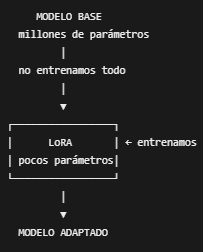

In [ ]:
# ============================================================
# 8. CONFIGURACIÓN DE LoRA
# ============================================================

# Eliminamos torchao para evitar posibles conflictos de
# compatibilidad durante esta práctica en Google Colab.
!pip uninstall -y torchao --quiet


# ------------------------------------------------------------
# Importamos las herramientas necesarias
# ------------------------------------------------------------

# LoraConfig permite definir cómo utilizaremos LoRA.
#
# get_peft_model aplica esa configuración a nuestro modelo.
from peft import LoraConfig, get_peft_model

# set_seed permite fijar una semilla para reducir variaciones
# entre diferentes ejecuciones del experimento.
from transformers import set_seed

set_seed(42)


# ------------------------------------------------------------
# Configuramos LoRA
# ------------------------------------------------------------

config_lora = LoraConfig(

    # r controla el tamaño de la adaptación LoRA.
    # Para esta práctica utilizaremos un valor pequeño.
    r=8,

    # Factor utilizado para controlar la influencia
    # de la adaptación LoRA.
    lora_alpha=16,

    # Indicamos en qué partes del modelo queremos
    # introducir las adaptaciones LoRA.
    target_modules=["q_proj", "v_proj"],

    # Durante esta práctica no aplicaremos dropout
    # a las capas LoRA.
    lora_dropout=0.0,

    # Indicamos que estamos trabajando con un modelo
    # cuya tarea es generar texto.
    task_type="CAUSAL_LM"
)


# ------------------------------------------------------------
# Aplicamos LoRA al modelo
# ------------------------------------------------------------

# Tomamos nuestro modelo base y agregamos los componentes
# entrenables definidos mediante LoRA.
modelo_lora = get_peft_model(
    modelo,
    config_lora
)


# ------------------------------------------------------------
# Revisamos cuántos parámetros serán entrenados
# ------------------------------------------------------------

# Esta instrucción muestra:
# - parámetros entrenables;
# - parámetros totales;
# - porcentaje del modelo que realmente vamos a entrenar.
modelo_lora.print_trainable_parameters()

trainable params: 1,126,400 || all params: 1,101,174,784 || trainable%: 0.1023


“¿Estamos entrenando todo TinyLlama?”

No.
Solo una pequeña fracción de sus parámetros.

TinyLlama ya está entrenado → no queremos volver a entrenar 1.1B de parámetros → agregamos adaptaciones LoRA → entrenamos solo una pequeña parte.

## 9. Entrenamiento del modelo con LoRA

Ya tenemos todos los elementos necesarios:

- **Modelo base:** TinyLlama.
- **Dataset:** ejemplos de preguntas y respuestas.
- **LoRA:** parámetros adicionales que serán ajustados.

Ahora realizaremos el **Fine-Tuning**.

### ¿Qué ocurre durante el entrenamiento?

El modelo recibe nuestros ejemplos y trata de generar las respuestas esperadas.

De manera simplificada:

**Ejemplo de entrenamiento**

`Pregunta → Modelo → Respuesta generada`

Luego se compara la respuesta generada con la respuesta esperada:

`Respuesta generada ↔ Respuesta esperada`

La diferencia entre ambas se representa mediante un valor llamado **pérdida (loss)**.

Durante el entrenamiento, el sistema ajusta los parámetros de LoRA buscando reducir esa pérdida.

**Mayor pérdida → el modelo está cometiendo más error**

**Menor pérdida → el modelo se está ajustando mejor a los ejemplos**

### Algunos parámetros del entrenamiento

**Épocas (epochs)**  
Indican cuántas veces el modelo recorrerá el conjunto completo de ejemplos.

**Batch size**  
Indica cuántos ejemplos se procesarán juntos antes de realizar una actualización.

**Learning rate**  
Controla el tamaño de los ajustes realizados durante el entrenamiento.

En esta práctica utilizaremos valores definidos previamente para realizar una demostración controlada.

### Importante

Nuestro dataset contiene solamente **5 ejemplos** y utilizaremos muchas épocas.

Esto es útil para observar claramente el efecto del Fine-Tuning en una demostración, pero **no representa un entrenamiento realista de producción**.

Nuestro objetivo es comprender el proceso.

In [ ]:
# ============================================================
# 9. ENTRENAMIENTO DEL MODELO CON LoRA
# ============================================================

# Nuestro dataset YA fue preparado en la celda 6.
#
# Cada ejemplo contiene:
#
# - input_ids
# - attention_mask
# - labels
#
# Además, nosotros mismos indicamos mediante -100 qué tokens
# NO deben participar en el cálculo de la pérdida.
#
# Por esta razón utilizaremos Trainer directamente.
#
# No necesitamos que SFTTrainer vuelva a procesar
# nuestro dataset.


# ------------------------------------------------------------
# Importamos las herramientas necesarias
# ------------------------------------------------------------

from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorForSeq2Seq
)


# ============================================================
# 1. VERIFICACIÓN DEL DATASET
# ============================================================

# Antes de comenzar el entrenamiento comprobamos que
# nuestro dataset realmente contiene ejemplos.

print("=" * 70)
print("VERIFICACIÓN DEL DATASET")
print("=" * 70)

print(f"Número de ejemplos: {len(dataset)}")


# Revisamos el primer ejemplo.
primer_ejemplo = dataset[0]


# Contamos cuántos tokens están ignorados.
tokens_ignorados = sum(
    etiqueta == -100
    for etiqueta in primer_ejemplo["labels"]
)


# Contamos cuántos tokens sí participarán
# en el cálculo de la pérdida.
tokens_entrenables = sum(
    etiqueta != -100
    for etiqueta in primer_ejemplo["labels"]
)


print(
    f"Tokens totales del primer ejemplo: "
    f"{len(primer_ejemplo['labels'])}"
)

print(
    f"Tokens ignorados: "
    f"{tokens_ignorados}"
)

print(
    f"Tokens entrenables: "
    f"{tokens_entrenables}"
)


# ------------------------------------------------------------
# Medida de seguridad
# ------------------------------------------------------------

# Si no existen tokens entrenables, detenemos el proceso.
#
# Esto evita comenzar un entrenamiento con un dataset
# incorrectamente preparado.

if tokens_entrenables == 0:
    raise ValueError(
        "No existen tokens entrenables. "
        "Revisa los labels generados en la celda 6."
    )


print("\nDataset preparado correctamente.")
print("=" * 70)


# ============================================================
# 2. CONFIGURACIÓN DEL ENTRENAMIENTO
# ============================================================

config_entrenamiento = TrainingArguments(

    # Carpeta donde se almacenarán los resultados
    # generados durante el entrenamiento.
    output_dir="/content/resultados_pipeline",


    # --------------------------------------------------------
    # ÉPOCAS
    # --------------------------------------------------------

    # Una época representa una pasada completa
    # por todos los ejemplos del dataset.
    #
    # Utilizamos 30 épocas porque se trata de una
    # demostración didáctica con un dataset pequeño.
    num_train_epochs=30,


    # --------------------------------------------------------
    # BATCH SIZE
    # --------------------------------------------------------

    # Procesaremos 5 ejemplos antes de realizar
    # cada actualización.
    #
    # Tenemos 50 ejemplos:
    #
    # 50 / 5 = 10 batches por época
    #
    # aproximadamente:
    #
    # 10 × 30 = 300 pasos de entrenamiento
    per_device_train_batch_size=5,


    # --------------------------------------------------------
    # LEARNING RATE
    # --------------------------------------------------------

    # Controla qué tan grandes serán los cambios
    # realizados durante el entrenamiento.
    learning_rate=5e-5,


    # --------------------------------------------------------
    # REGISTRO DE LA PÉRDIDA
    # --------------------------------------------------------

    # Registramos información después de cada paso.
    #
    # Posteriormente utilizaremos estos datos
    # para construir la gráfica de pérdida.
    logging_steps=1,

    logging_strategy="steps",


    # --------------------------------------------------------
    # GUARDADO
    # --------------------------------------------------------

    # Para esta demostración no necesitamos guardar
    # checkpoints durante las 30 épocas.
    #
    # El adaptador LoRA se guardará posteriormente
    # en otra celda.
    save_strategy="no",


    # --------------------------------------------------------
    # SERVICIOS EXTERNOS
    # --------------------------------------------------------

    # No enviaremos información del entrenamiento
    # a plataformas externas como WandB.
    report_to="none",


    # --------------------------------------------------------
    # COLUMNAS DEL DATASET
    # --------------------------------------------------------

    # Conservamos las columnas que nosotros mismos
    # preparamos:
    #
    # input_ids
    # attention_mask
    # labels
    remove_unused_columns=False,
)


# ============================================================
# 3. PREPARACIÓN DE LOS BATCHES
# ============================================================

# Los ejemplos pueden tener diferentes longitudes.
#
# El DataCollator se encarga de agregar padding
# cuando sea necesario para formar cada batch.
#
# Para los labels utilizamos -100 como padding.
#
# PyTorch ignora los valores -100 cuando calcula
# la pérdida.

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)


# ============================================================
# 4. CREAMOS EL ENTRENADOR
# ============================================================

# Utilizamos Trainer en lugar de SFTTrainer.
#
# ¿Por qué?
#
# Porque nuestro dataset YA está:
#
# 1. Tokenizado.
# 2. Preparado.
# 3. Enmascarado.
#
# No queremos que otra herramienta vuelva a modificarlo.

trainer = Trainer(
    model=modelo_lora,
    args=config_entrenamiento,
    train_dataset=dataset,
    data_collator=data_collator
)


# ============================================================
# 5. INICIAMOS EL FINE-TUNING
# ============================================================

print("\n" + "=" * 70)
print("INICIANDO FINE-TUNING")
print("=" * 70)

resultado_entrenamiento = trainer.train()


# ============================================================
# 6. RECUPERAMOS LA PÉRDIDA REAL DEL ENTRENAMIENTO
# ============================================================

# Trainer almacena diferentes registros durante
# el entrenamiento.
#
# Seleccionamos únicamente aquellos que contienen
# un valor de "loss".

historial_loss = [
    registro["loss"]
    for registro in trainer.state.log_history
    if "loss" in registro
]


# ============================================================
# 7. COMPROBAMOS QUE EXISTAN REGISTROS DE PÉRDIDA
# ============================================================

if len(historial_loss) == 0:

    print(
        "El entrenamiento terminó, pero no se "
        "registraron valores de pérdida."
    )

else:

    # Primer valor registrado.
    perdida_inicial = historial_loss[0]

    # Último valor registrado.
    perdida_final = historial_loss[-1]


    # ========================================================
    # 8. CALCULAMOS LA REDUCCIÓN DE LA PÉRDIDA
    # ========================================================

    reduccion_loss = (
        1 - (perdida_final / perdida_inicial)
    ) * 100


    # ========================================================
    # 9. MOSTRAMOS LOS RESULTADOS
    # ========================================================

    print("\n" + "=" * 70)
    print("RESULTADOS DEL FINE-TUNING CON LoRA")
    print("=" * 70)

    print(
        f"Número de ejemplos: "
        f"{len(dataset)}"
    )

    print(
        f"Número de épocas: "
        f"{config_entrenamiento.num_train_epochs}"
    )

    print(
        f"Batch size: "
        f"{config_entrenamiento.per_device_train_batch_size}"
    )

    print(
        f"Learning rate: "
        f"{config_entrenamiento.learning_rate}"
    )


    print("\n" + "-" * 70)
    print("PÉRDIDA DURANTE EL ENTRENAMIENTO")
    print("-" * 70)

    print(
        f"Pérdida inicial: "
        f"{perdida_inicial:.4f}"
    )

    print(
        f"Pérdida final:   "
        f"{perdida_final:.4f}"
    )

    print(
        f"Reducción:       "
        f"{reduccion_loss:.1f}%"
    )

    print("=" * 70)

VERIFICACIÓN DEL DATASET
Número de ejemplos: 50
Tokens totales del primer ejemplo: 196
Tokens ignorados: 175
Tokens entrenables: 21

Dataset preparado correctamente.

INICIANDO FINE-TUNING
{'loss': '3.149', 'grad_norm': '3.291', 'learning_rate': '5e-05', 'epoch': '0.1'}
{'loss': '3.171', 'grad_norm': '2.953', 'learning_rate': '4.983e-05', 'epoch': '0.2'}
{'loss': '3.133', 'grad_norm': '3.323', 'learning_rate': '4.967e-05', 'epoch': '0.3'}
{'loss': '3.066', 'grad_norm': '3.602', 'learning_rate': '4.95e-05', 'epoch': '0.4'}
{'loss': '2.74', 'grad_norm': '3.424', 'learning_rate': '4.933e-05', 'epoch': '0.5'}
{'loss': '3.503', 'grad_norm': '3.377', 'learning_rate': '4.917e-05', 'epoch': '0.6'}
{'loss': '3.13', 'grad_norm': '4.297', 'learning_rate': '4.9e-05', 'epoch': '0.7'}
{'loss': '2.918', 'grad_norm': '3.711', 'learning_rate': '4.883e-05', 'epoch': '0.8'}
{'loss': '3.175', 'grad_norm': '3.614', 'learning_rate': '4.867e-05', 'epoch': '0.9'}
{'loss': '3.019', 'grad_norm': '3.83', 'learni

## 10. Visualización del aprendizaje durante el Fine-Tuning

Durante el entrenamiento, `SFTTrainer` fue registrando información sobre cada etapa del proceso.

Entre esos datos se encuentra la **pérdida (loss)** obtenida durante el entrenamiento.

Ahora utilizaremos esos datos reales para construir una **curva de aprendizaje**.

En la gráfica:

- **Eje X — Época:** indica cuántas veces el modelo ha recorrido el conjunto de entrenamiento.
- **Eje Y — Pérdida (Loss):** representa qué tan diferente es el comportamiento del modelo respecto a los ejemplos utilizados para entrenarlo.

Si el entrenamiento está logrando ajustarse a nuestros ejemplos, esperamos observar una tendencia general:

**Avanza el entrenamiento → disminuye la pérdida**

### Importante

La pérdida no tiene que disminuir exactamente en cada punto. Puede presentar pequeñas variaciones.

Lo importante es observar su **tendencia general**.

Además, una pérdida baja indica que el modelo se está ajustando a los datos de entrenamiento, pero **no garantiza que responda correctamente preguntas nuevas**.

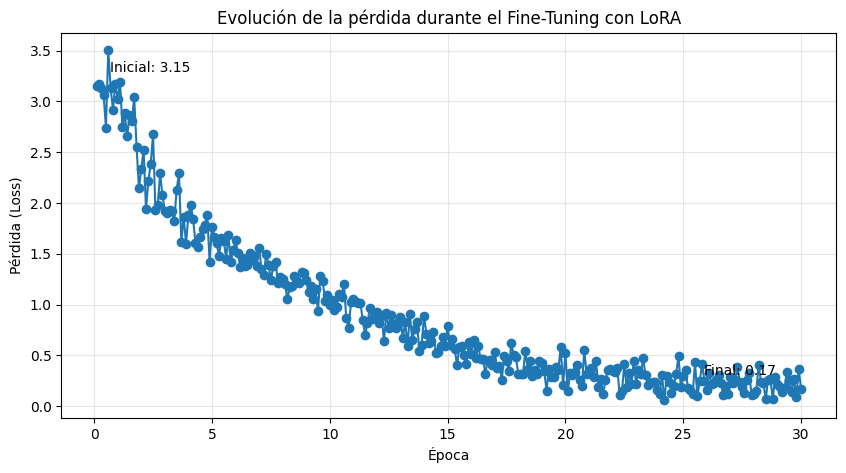

In [ ]:
# ============================================================
# 10. GRÁFICA DE LA PÉRDIDA REAL DURANTE EL FINE-TUNING
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Recuperamos los datos generados durante el entrenamiento
# ------------------------------------------------------------

# trainer.state.log_history contiene los registros REALES
# generados por SFTTrainer durante el Fine-Tuning.
#
# Algunos registros contienen información adicional, por lo que
# seleccionamos únicamente aquellos que tienen un valor de "loss".
registros_loss = [
    registro
    for registro in trainer.state.log_history
    if "loss" in registro
]


# ------------------------------------------------------------
# Extraemos las épocas y sus pérdidas
# ------------------------------------------------------------

# Recuperamos la época correspondiente a cada registro.
epocas = [
    registro["epoch"]
    for registro in registros_loss
]


# Recuperamos el valor de pérdida registrado en cada época.
perdidas = [
    registro["loss"]
    for registro in registros_loss
]


# ------------------------------------------------------------
# Creamos la gráfica
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

# Cada punto representa un valor REAL registrado
# durante nuestro entrenamiento.
plt.plot(
    epocas,
    perdidas,
    marker="o"
)


# ------------------------------------------------------------
# Agregamos información para interpretar la gráfica
# ------------------------------------------------------------

plt.title("Evolución de la pérdida durante el Fine-Tuning con LoRA")

plt.xlabel("Época")
plt.ylabel("Pérdida (Loss)")

# La cuadrícula facilita comparar los valores.
plt.grid(True, alpha=0.3)


# ------------------------------------------------------------
# Marcamos la pérdida inicial y final
# ------------------------------------------------------------

# Marcamos el primer valor registrado.
plt.annotate(
    f"Inicial: {perdidas[0]:.2f}",
    xy=(epocas[0], perdidas[0]),
    xytext=(10, 10),
    textcoords="offset points"
)

# Marcamos el último valor registrado.
plt.annotate(
    f"Final: {perdidas[-1]:.2f}",
    xy=(epocas[-1], perdidas[-1]),
    xytext=(-70, 10),
    textcoords="offset points"
)


# Mostramos la gráfica.
plt.show()

## 11. Guardar el adaptador LoRA

Ya realizamos el Fine-Tuning y observamos cómo cambió la pérdida durante el entrenamiento.

Ahora queremos conservar el resultado del ajuste para poder utilizarlo posteriormente.

### ¿Qué vamos a guardar?

Recordemos que con LoRA no entrenamos nuevamente todos los parámetros de TinyLlama.

Durante el Fine-Tuning mantuvimos el modelo base y entrenamos una pequeña cantidad de parámetros adicionales:

**TinyLlama (modelo base)**  
+
**Adaptador LoRA entrenado**  
=
**Modelo adaptado a nuestros ejemplos**

Por esta razón, no necesitamos guardar nuevamente una copia completa de todos los parámetros del modelo base.

Podemos guardar principalmente el **adaptador LoRA** que acabamos de entrenar.

### ¿Para qué sirve guardarlo?

El adaptador puede utilizarse posteriormente junto con el mismo modelo base para recuperar el comportamiento que obtuvimos después del Fine-Tuning.

De forma conceptual:

`TinyLlama + Adaptador LoRA guardado → Modelo ajustado`

También podríamos almacenar el adaptador en Hugging Face para reutilizarlo desde otras sesiones o equipos.

En esta práctica primero lo guardaremos localmente dentro de Google Colab.

In [ ]:
# ============================================================
# 11. GUARDAR EL ADAPTADOR LoRA
# ============================================================

# Después del Fine-Tuning, los parámetros entrenados mediante
# LoRA se encuentran dentro de modelo_lora.
#
# Como utilizamos LoRA, no necesitamos guardar nuevamente
# una copia completa de todos los parámetros de TinyLlama.
# Guardaremos el adaptador que contiene los ajustes aprendidos.


# ------------------------------------------------------------
# Guardamos el adaptador localmente
# ------------------------------------------------------------

modelo_lora.save_pretrained(
    "/content/modelo_ajustado_lora"
)

print(
    "Adaptador LoRA guardado correctamente en "
    "/content/modelo_ajustado_lora"
)


# ------------------------------------------------------------
# OPCIONAL: Subir el adaptador a Hugging Face
# ------------------------------------------------------------

# Si queremos conservar el adaptador fuera de esta sesión
# de Google Colab, podemos subirlo a nuestra cuenta
# de Hugging Face.
#
# Esto permitiría descargarlo y reutilizarlo posteriormente
# junto con el mismo modelo base.
#
# Para utilizar esta opción debemos reemplazar
# "tu-usuario" por nuestro usuario de Hugging Face.

# modelo_lora.push_to_hub(
#     "tu-usuario/tinyllama-biblioteca-lora"
# )

Adaptador LoRA guardado correctamente en /content/modelo_ajustado_lora


# Pipeline completo: Chatbot con RAG

Hasta ahora hemos construido y analizado diferentes componentes por separado.

En esta última etapa los integraremos para construir un **chatbot con RAG (Retrieval-Augmented Generation)**.

El flujo completo será:

**Pregunta del usuario → Recuperación → Contexto → Prompt → Modelo de lenguaje → Respuesta**

---

## ¿Qué ocurre cuando hacemos una pregunta?

### 1. Pregunta

El estudiante realiza una pregunta sobre las políticas de la biblioteca.

Ejemplo:

> ¿Puedo renovar el préstamo de un libro?

### 2. Recuperación

La función `buscar_fragmento()` utiliza los **embeddings** para buscar en nuestra base de conocimiento el fragmento más relacionado con la pregunta.

Esta es la parte de **Retrieval (recuperación)** de RAG.

### 3. Contexto

El fragmento recuperado se utiliza como información adicional para responder la pregunta.

Por ejemplo:

> Los libros se prestan por un máximo de 15 días, con posibilidad de renovar una vez si nadie más lo ha solicitado.

### 4. Construcción del prompt

Combinamos tres elementos:

**Instrucciones + Contexto recuperado + Pregunta**

Las instrucciones indican al modelo cómo debe comportarse, mientras que el contexto proporciona la información que debe utilizar para responder.

### 5. Generación

Enviamos toda esta información a un **modelo de lenguaje**, que genera la respuesta final.

En esta demostración utilizaremos un modelo desplegado mediante una API.

Esta es la parte de **Generation (generación)** de RAG.

### 6. Respuesta

Finalmente, el chatbot devuelve la respuesta al estudiante.

---

## Flujo del sistema

`Pregunta → Embeddings → Recuperación → Contexto → Prompt → LLM → Respuesta`

---

## ¿Dónde queda el Fine-Tuning?

En la sección anterior utilizamos **TinyLlama + LoRA** para observar cómo el Fine-Tuning puede modificar el comportamiento de un modelo mediante entrenamiento.

En esta sección estamos mostrando otra técnica: **RAG**.

Son técnicas diferentes:

| Técnica | ¿Qué hacemos? |
|---|---|
| **Prompting** | Damos instrucciones al modelo |
| **Fine-Tuning** | Ajustamos parámetros del modelo utilizando ejemplos |
| **RAG** | Recuperamos información externa y la proporcionamos como contexto |

> **Importante:** el modelo utilizado para generar las respuestas en este chatbot RAG no tiene que ser el mismo modelo que ajustamos con LoRA.

El objetivo de esta última etapa es observar cómo diferentes componentes pueden integrarse para construir un sistema de Inteligencia Artificial completo.

In [ ]:
# ============================================================
# PIPELINE COMPLETO DEL CHATBOT CON RAG
# ============================================================
#
# En esta última parte integramos todos los componentes:
#
# Pregunta
#    ↓
# Recuperación de información
#    ↓
# Contexto relevante
#    ↓
# Construcción del prompt
#    ↓
# Modelo de lenguaje
#    ↓
# Respuesta


# ============================================================
# 1. INSTALAMOS E IMPORTAMOS GROQ
# ============================================================

!pip install groq -q

from groq import Groq


# Creamos el cliente utilizando la API Key
# almacenada en los secretos de Google Colab.

client = Groq(
    api_key=userdata.get("GROQ_API_KEY")
)


# ============================================================
# 2. PROMPT PRINCIPAL DEL CHATBOT
# ============================================================
#
# El SYSTEM PROMPT define cómo debe comportarse
# nuestro asistente.
#
# No contiene la pregunta ni el reglamento recuperado.
# Solamente establece las instrucciones generales.

PROMPT_RAG = """
Eres un asistente virtual de una biblioteca universitaria.

Tu función es ayudar a los estudiantes respondiendo preguntas
sobre las políticas y servicios de la biblioteca.

Sigue estas reglas:

- Utiliza únicamente la información proporcionada en el contexto.
- No inventes información.
- Si el contexto no contiene la respuesta, indícalo claramente.
- Responde de forma breve y directa.
- Utiliza un lenguaje claro y sencillo.
- Mantén un tono amable y profesional.
"""


# ============================================================
# 3. FUNCIÓN DEL ASISTENTE
# ============================================================

def asistente(pregunta):

    # --------------------------------------------------------
    # PASO 1: RECUPERACIÓN
    # --------------------------------------------------------
    #
    # Convertimos la pregunta en una búsqueda sobre nuestra
    # base de conocimiento.
    #
    # buscar_fragmento() fue construida anteriormente
    # utilizando embeddings.

    fragmento = buscar_fragmento(pregunta)


    # --------------------------------------------------------
    # PASO 2: CONSTRUCCIÓN DEL CONTEXTO
    # --------------------------------------------------------
    #
    # Combinamos:
    #
    # - la información recuperada;
    # - la pregunta del estudiante.

    mensaje_usuario = f"""
CONTEXTO RECUPERADO:

{fragmento}

PREGUNTA DEL ESTUDIANTE:

{pregunta}
"""


    # --------------------------------------------------------
    # PASO 3: GENERACIÓN
    # --------------------------------------------------------
    #
    # Enviamos al modelo dos mensajes:
    #
    # SYSTEM -> indica cómo debe comportarse.
    # USER   -> contiene el contexto y la pregunta.

    response = client.chat.completions.create(

        model="openai/gpt-oss-20b",

        messages=[
            {
                "role": "system",
                "content": PROMPT_RAG
            },
            {
                "role": "user",
                "content": mensaje_usuario
            }
        ]
    )


    # --------------------------------------------------------
    # PASO 4: RESPUESTA
    # --------------------------------------------------------

    respuesta = response.choices[0].message.content

    return respuesta


# ============================================================
# 4. PROBAMOS EL PIPELINE COMPLETO
# ============================================================

preguntas_prueba = [

    "¿Puedo llevarme a casa un libro de la sección de reserva (material de examen)?",

    "¿Cuánto es la multa por entregar un libro tarde?",

    "¿Puedo renovar el préstamo de un libro?"
]


for pregunta in preguntas_prueba:

    print("=" * 70)

    print(f"PREGUNTA:")
    print(pregunta)

    print("\nRESPUESTA:")
    print(asistente(pregunta))

    print()

PREGUNTA:
¿Puedo llevarme a casa un libro de la sección de reserva (material de examen)?

RESPUESTA:
No, los libros de la sección de reserva (material de examen) sólo se pueden consultar dentro de la biblioteca y no se prestan a domicilio.

PREGUNTA:
¿Cuánto es la multa por entregar un libro tarde?

RESPUESTA:
La multa es de $10 por cada día de retraso, con un máximo de $150 por libro.

PREGUNTA:
¿Puedo renovar el préstamo de un libro?

RESPUESTA:
Sí, puedes renovar el préstamo una sola vez, siempre y cuando nadie más lo haya solicitado.



In [ ]:
# ============================================================
# PRUEBA INTERACTIVA DEL CHATBOT
# ============================================================

# input() permite que el usuario escriba una pregunta
# directamente desde Google Colab.

pregunta_usuario = input(
    "Escribe tu pregunta sobre la biblioteca: "
)


# Enviamos la pregunta al pipeline completo
# que construimos anteriormente.

respuesta = asistente(pregunta_usuario)


# Mostramos el resultado.

print("\n" + "=" * 70)
print("RESPUESTA DEL CHATBOT")
print("=" * 70)

print(respuesta)

print("=" * 70)

Escribe tu pregunta sobre la biblioteca: que dia abren

RESPUESTA DEL CHATBOT
Lo siento, pero en el contexto proporcionado no se indica el día de apertura de la biblioteca.
